[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/03_functions.ipynb)

*Math for Data Science & ML · Notebook 3 of 10*

# Functions & Graphs

A function is a machine: input in, one output out. Lines and slope, parabolas, exponentials, logarithms, and the activation functions used in neural networks.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A function is a machine: put in x, get out y. Its graph is a picture of everything that machine does.

**What interviewers really test here:** Sigmoid, exp, log: their shapes and why they appear in ML.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What is a function? *(Basics)*
- [ ] 2. Straight lines: slope and intercept *(Basics)*
- [ ] 3. Reading a graph and substituting *(Basics)*
- [ ] 4. Parabolas and transforming graphs *(Core)*
- [ ] 5. Exponentials and logarithms *(Core)*
- [ ] 6. Logarithms by hand *(Core)*
- [ ] 7. Composition and inverses by hand *(Core)*
- [ ] 8. Activation functions: the functions inside neural networks *(Advanced)*
- [ ] 9. How fast do functions grow? *(Advanced)*
- [ ] 10. The number e and exponential decay *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Definition

A **function** f from a set X (the **domain**) to a set Y assigns to every x in X exactly one f(x) in Y. The set of outputs actually produced is the **range**. Graphically: any vertical line meets the graph at most once (the vertical line test).




- **One-to-one** (injective): different inputs give different outputs — only these have an inverse.
- **Inverse** f⁻¹ undoes f: f⁻¹(f(x)) = x. Its graph is f's mirrored in the line y = x.
- **Composition** (f ∘ g)(x) = f(g(x)) — apply g first.

### Families of functions

| Family | Formula | Shape | Seen in ML as |
| --- | --- | --- | --- |
| Linear | mx + c | straight line | linear regression, a neuron before activation |
| Quadratic | ax² + bx + c | parabola | squared-error loss |
| Polynomial | aₙxⁿ + … + a₀ | wiggles (≤ n − 1 turns) | polynomial features |
| Exponential | a·bˣ, eˣ | explodes or decays | softmax, growth models |
| Logarithmic | log\_b x | slow growth | log-loss, log transforms |
| Sigmoid / tanh | 1/(1+e⁻ˣ) | S-curve | logistic regression, gates |
| Piecewise | different rule per interval | corners | ReLU, decision trees |

### Lines

- Slope m = Δy/Δx = (y₂ − y₁)/(x₂ − x₁); slope-intercept form y = mx + c; point-slope form y − y₁ = m(x − x₁).
- Parallel lines have equal slopes; perpendicular lines have m₁·m₂ = −1.
- The **average rate of change** of any f on [a, b] is the slope of the line through (a, f(a)) and (b, f(b)) — the doorway to derivatives.

### Exponentials and logarithms

y = bˣ ⇔ x = log\_b y. Natural log ln = log\_e, where e = lim (1 + 1/n)ⁿ ≈ 2.71828.



|   |   |
| --- | --- |
| log\_b(xy) = log\_b x + log\_b y | log\_b(x/y) = log\_b x − log\_b y |
| log\_b(xⁿ) = n log\_b x | log\_b x = ln x / ln b (change of base) |
| log\_b 1 = 0, log\_b b = 1 | log is only defined for x &gt; 0 |

### Transformations and symmetry

g(x) = a·f(b(x − h)) + k: shift right h, up k, stretch vertically by a (reflect if a &lt; 0), compress horizontally by b. **Even** functions satisfy f(−x) = f(x) (mirror in the y-axis, e.g. x², cos x); **odd** functions satisfy f(−x) = −f(x) (rotational symmetry, e.g. x³, sin x, tanh x).

---
# Part 2: Lessons, step by step

## Lesson 1: What is a function?

*Level: Basics*

A **function** is a machine: you put a number in, it gives exactly **one** number out. We write f(x) = 2x + 1: "f of x is two x plus one". f(3) = 7.




- The allowed inputs are the **domain** (you can't take √ of a negative or divide by zero).
- The possible outputs are the **range**.
- A **graph** plots every (input, output) pair as a point (x, f(x)).



A Python function `def f(x): return 2*x + 1` is the same idea. A **machine-learning model is a function**: input features → prediction. Training means choosing the function's numbers well.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

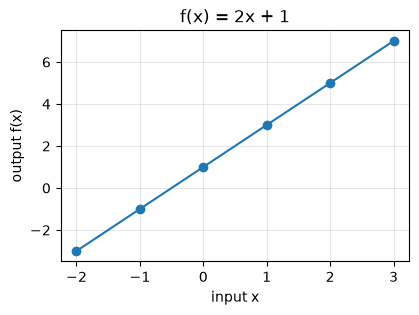

In [2]:
def function_machine():
    def f(x):
        return 2 * x + 1
    inputs = [-2, -1, 0, 1, 2, 3]
    outputs = [f(x) for x in inputs]
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(inputs, outputs, "o-")
    ax.set_xlabel("input x")
    ax.set_ylabel("output f(x)")
    ax.set_title("f(x) = 2x + 1")
    ax.grid(alpha=0.3)


function_machine()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. f() returns -3
2. f() returns -1
3. f() returns 1
4. f() returns 3
5. f() returns 5
6. f() returns 7
7. function\_machine() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q4](#q4), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 2: Straight lines: slope and intercept

*Level: Basics*

The simplest graph is a straight line: **y = mx + c**.




- **m**, the **slope**, is how much y goes up when x goes up by 1: rise ÷ run. Positive slopes go up, negative go down, zero is flat.
- **c**, the **intercept**, is where the line crosses the y-axis (the value when x = 0).



Through two points (x₁, y₁), (x₂, y₂): m = (y₂ − y₁)/(x₂ − x₁), then c = y₁ − m·x₁.



**Linear regression**, the first ML model everyone learns, is nothing more than choosing the m and c that best fit the data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

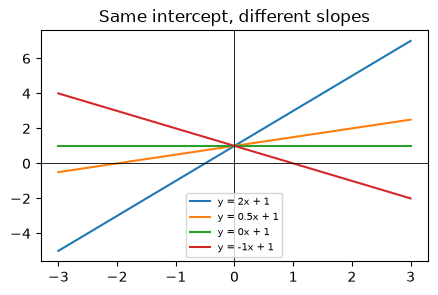

In [3]:
def slopes_demo():
    x = np.linspace(-3, 3, 20)
    fig, ax = plt.subplots(figsize=(5, 3))
    for m, c in [(2, 1), (0.5, 1), (0, 1), (-1, 1)]:
        ax.plot(x, m * x + c, label=f"y = {m}x + {c}")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.legend(fontsize=7)
    ax.set_title("Same intercept, different slopes")


slopes_demo()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q13](#q13), [Q6](#q6), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 3: Reading a graph and substituting

*Level: Basics*

#### The coordinate plane



A point (3, 2) means 3 right, 2 up. For a function, x is the input and y = f(x) is the output.



| You see | It means |
| --- | --- |
| Line going up to the right | output grows with input (positive slope) |
| Flat part | no change: slope 0 |
| Crosses the y-axis | the value at x = 0 |
| Crosses the x-axis | a root, where f(x) = 0 |
| Lowest or highest point | a minimum or maximum |



#### Substituting anything



f(x) = x² + 1. The x is a slot, and whatever you put in goes everywhere x appears:



- f(3) = 9 + 1 = 10
- f(−2) = 4 + 1 = 5
- f(a + 1) = (a + 1)² + 1 = a² + 2a + 2



#### Domain: what inputs are allowed?



- √(x − 2) needs x ≥ 2.
- 1 / (x − 5) needs x ≠ 5.
- log(x) needs x &gt; 0.



These cause most `NaN` and `inf` values in real code.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

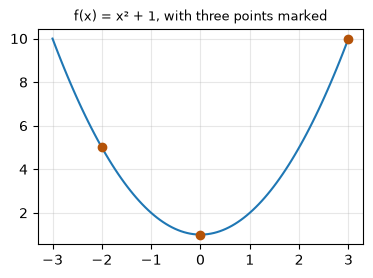

In [4]:
def substitute_demo():
    def f(x):
        return x ** 2 + 1

    values = {x: f(x) for x in [3, -2, 0]}
    a = 4
    direct = f(a + 1)
    expanded = a ** 2 + 2 * a + 2
    xs = np.linspace(-3, 3, 100)
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.plot(xs, f(xs))
    ax.plot(list(values), list(values.values()), "o", color="#b45309")
    ax.set_title("f(x) = x² + 1, with three points marked", fontsize=9)
    ax.grid(alpha=0.3)


substitute_demo()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. f() returns 10
2. f() returns 5
3. f() returns 1
4. f() returns 26
5. f() returns array([10.        ,  9.64003673,  9.2...
6. substitute\_demo() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q14](#q14), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 4: Parabolas and transforming graphs

*Level: Core*

y = x² is a U-shape with its lowest point, the **vertex**, at (0, 0). For y = ax² + bx + c the vertex is at x = −b/2a; a &gt; 0 opens up (has a minimum), a &lt; 0 opens down (a maximum).



Any graph can be moved and stretched: **g(x) = a·f(x − h) + k**



| Change | Effect |
| --- | --- |
| x − h | shift right by h |
| + k | shift up by k |
| a × | stretch vertically (flip if negative) |



Finding the lowest point of a U-shaped curve is exactly what "minimising a loss" means in ML.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

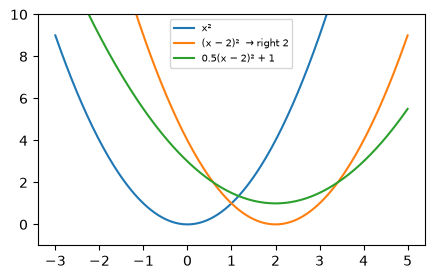

In [5]:
def transform_demo():
    x = np.linspace(-3, 5, 200)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, x ** 2, label="x²")
    ax.plot(x, (x - 2) ** 2, label="(x − 2)²  → right 2")
    ax.plot(x, 0.5 * (x - 2) ** 2 + 1, label="0.5(x − 2)² + 1")
    ax.set_ylim(-1, 10)
    ax.legend(fontsize=7)


transform_demo()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q18](#q18), [Q19](#q19), [Q11](#q11), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 5: Exponentials and logarithms

*Level: Core*

An **exponential** function multiplies by the same factor every step: f(x) = a·bˣ. With b &gt; 1 it explodes (population, compound interest); with 0 &lt; b &lt; 1 it decays (radioactivity, learning-rate schedules). The special base **e ≈ 2.718** appears everywhere in ML: eˣ = `np.exp(x)`.



A **logarithm** answers the reverse question: "b to what power gives n?" log₂ 8 = 3 because 2³ = 8. ln means log base e.



| Log rule | Why it matters |
| --- | --- |
| log(ab) = log a + log b | turns products of many probabilities into sums (no underflow) |
| log(aⁿ) = n log a | brings exponents down so you can solve for them |



Logs squash huge ranges (1 to 1 000 000 becomes 0 to 6) — that's why skewed data such as incomes is often log-transformed.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

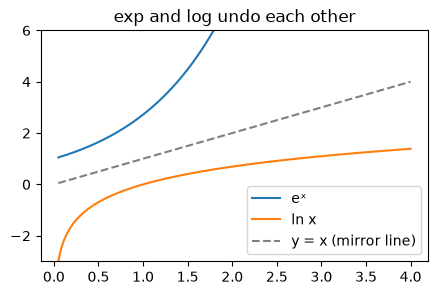

In [6]:
def exp_log_demo():
    x = np.linspace(0.05, 4, 200)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, np.exp(x), label="eˣ")
    ax.plot(x, np.log(x), label="ln x")
    ax.plot(x, x, "--", color="gray", label="y = x (mirror line)")
    ax.set_ylim(-3, 6)
    ax.legend()
    ax.set_title("exp and log undo each other")


exp_log_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q8](#q8), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 6: Logarithms by hand

*Level: Core*

A log answers: **what power do I need?**



| Log | Reads as | Answer |
| --- | --- | --- |
| log₂ 8 | 2 to what power gives 8? | 3 |
| log₁₀ 1000 | 10 to what power gives 1000? | 3 |
| log₁₀ 0.01 | 10 to what power gives 0.01? | −2 |
| log₅ 1 | 5 to what power gives 1? | 0 |



#### The rules, checked with numbers



- **Product:** log₁₀(100 × 1000) = 5 = 2 + 3 ✓
- **Power:** log₂(8²) = log₂ 64 = 6 = 2 × 3 ✓
- **Change of base:** log₂ 10 = ln 10 / ln 2 = 2.303 / 0.693 = 3.322



**Rule of thumb:** log₂ n is how many times you can halve n before reaching 1. log₂ 1000 ≈ 10, which is why binary search is so fast.



**Mistake:** log(a + b) isn't log a + log b. Only products become sums.



#### Why logs matter in data



They compress big ranges and turn multiplying into adding. The chart shows the same exponential growth with normal and log scales; on a log scale it's a straight line.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

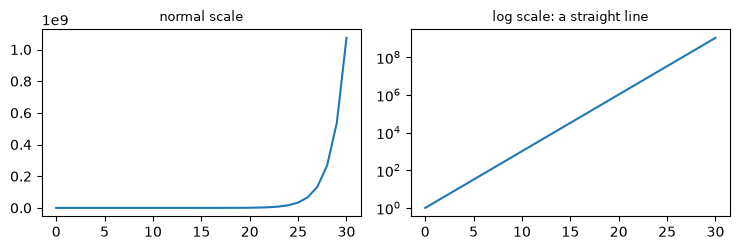

In [7]:
def log_checks():
    product_rule = (math.log10(100 * 1000), math.log10(100) + math.log10(1000))
    power_rule = (math.log2(8 ** 2), 2 * math.log2(8))
    change_of_base = math.log(10) / math.log(2)
    halvings = math.log2(1000)
    x = np.arange(0, 31)
    y = 2.0 ** x
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.6))
    left.plot(x, y)
    left.set_title("normal scale", fontsize=9)
    right.semilogy(x, y)
    right.set_title("log scale: a straight line", fontsize=9)
    fig.tight_layout()


log_checks()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 7: Composition and inverses by hand

*Level: Core*

f(x) = 2x + 3 and g(x) = x².



#### Composition: feed one into the other



| Expression | Inside first | Then | At x = 2 |
| --- | --- | --- | --- |
| f(g(x)) | g(2) = 4 | f(4) = 11 | 11 |
| g(f(x)) | f(2) = 7 | g(7) = 49 | 49 |



**Order matters.** A neural network is a long composition, with each layer feeding the next.



#### Inverse: undo the function



1. Write y = 2x + 3.
2. Solve for x: x = (y − 3) / 2.
3. So f⁻¹(x) = (x − 3) / 2.
4. Check: f(5) = 13 and f⁻¹(13) = 5 ✓.



A function needs one output to come from just one input to have an inverse. x² doesn't, since (−2)² = 2² = 4; restrict it to x ≥ 0 and √x undoes it.



**Inverses in ML:** exp and ln undo each other, and the sigmoid's inverse is the logit (log-odds).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def compose_inverse():
    def f(x):
        return 2 * x + 3

    def g(x):
        return x ** 2

    def f_inverse(x):
        return (x - 3) / 2

    f_of_g = f(g(2))
    g_of_f = g(f(2))
    round_trip = f_inverse(f(5))
    not_one_to_one = (g(-2), g(2))
    logit_of_sigmoid = math.log((1 / (1 + math.exp(-1.5))) / (1 - 1 / (1 + math.exp(-1.5))))


compose_inverse()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. g() returns 4
2. f() returns 11
3. f() returns 7
4. g() returns 49
5. f() returns 13
6. f\_inverse() returns 5.0
7. g() returns 4
8. g() returns 4
9. compose\_inverse() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 8: Activation functions: the functions inside neural networks

*Level: Advanced*

A neural network is a chain of simple functions. Between layers it applies an **activation function** so the network can bend and model curves, not just straight lines:



| Function | Formula | Output |
| --- | --- | --- |
| Sigmoid | 1 / (1 + e⁻ˣ) | (0, 1) — reads as a probability |
| tanh | (eˣ − e⁻ˣ)/(eˣ + e⁻ˣ) | (−1, 1) |
| ReLU | max(0, x) | [0, ∞) — the default in deep learning |
| Step | 1 if x ≥ 0 else 0 | {0, 1} — the original perceptron |



Piecewise functions like ReLU and tax brackets use different rules on different intervals. **Composition** f(g(x)) — feeding one function into another — is what "layers" are.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

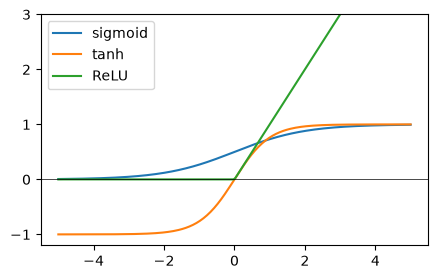

In [9]:
def activations():
    x = np.linspace(-5, 5, 200)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, 1 / (1 + np.exp(-x)), label="sigmoid")
    ax.plot(x, np.tanh(x), label="tanh")
    ax.plot(x, np.maximum(0, x), label="ReLU")
    ax.set_ylim(-1.2, 3)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.legend()


activations()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q10](#q10), [Q20](#q20), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 9: How fast do functions grow?

*Level: Advanced*

When data grows, which part dominates? This decides whether code finishes.



| n | log₂ n | n | n log₂ n | n² | 2ⁿ |
| --- | --- | --- | --- | --- | --- |
| 10 | 3.3 | 10 | 33 | 100 | 1,024 |
| 100 | 6.6 | 100 | 664 | 10,000 | about 10³⁰ |
| 1,000 | 10 | 1,000 | 9,966 | 1,000,000 | unimaginable |



Going from 10 to 1,000 rows multiplies n² work by 10,000.



#### Where you'll see them



- **log n:** binary search, tree depth
- **n log n:** sorting, tree building
- **n²:** comparing every pair of points (k-NN by brute force)
- **2ⁿ:** trying every subset of features, which is why nobody does



**Only the fastest-growing term matters** for large n: in n² + 100n, at n = 1,000,000 the first term is 10¹² and the second just 10⁸.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

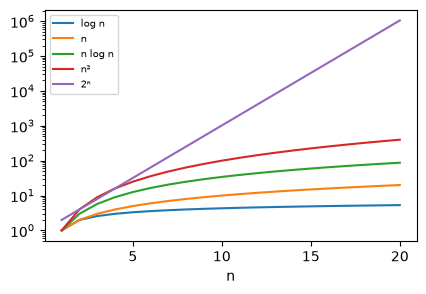

In [10]:
def growth_rates():
    n = np.arange(1, 21)
    fig, ax = plt.subplots(figsize=(4.8, 3))
    ax.semilogy(n, np.log2(n) + 1, label="log n")
    ax.semilogy(n, n, label="n")
    ax.semilogy(n, n * np.log2(n) + 1, label="n log n")
    ax.semilogy(n, n ** 2, label="n²")
    ax.semilogy(n, 2.0 ** n, label="2ⁿ")
    ax.set_xlabel("n")
    ax.legend(fontsize=7)


growth_rates()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 10: The number e and exponential decay

*Level: Advanced*

#### Where e comes from



₹1 at 100% yearly interest, added in n equal parts through the year, grows to (1 + 1/n)ⁿ:



| n | 1 | 2 | 10 | 100 | 1000 |
| --- | --- | --- | --- | --- | --- |
| Value | 2 | 2.25 | 2.5937 | 2.7048 | 2.7169 |



It approaches **e ≈ 2.71828**. eˣ is special: its slope at any point equals its height, which makes all of calculus with it easy.



#### Decay



Multiply by a number below 1 repeatedly. With half-life steps, 100 → 50 → 25 → **12.5** after 3 steps.



**In ML, a learning-rate schedule** does this: starting at 0.1 and multiplying by 0.9 each epoch gives 0.09 after 1 epoch, 0.059 after 5, and 0.035 after 10.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

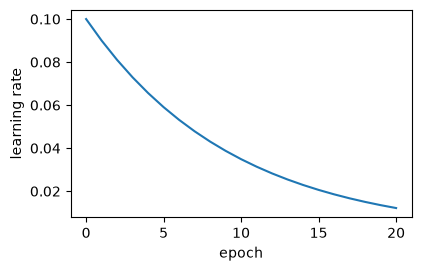

In [11]:
def e_and_decay():
    approaching = {n: round((1 + 1 / n) ** n, 4) for n in [1, 2, 10, 100, 1000]}
    half_life = [100 * 0.5 ** k for k in range(4)]
    rates = 0.1 * 0.9 ** np.arange(21)
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ax.plot(rates)
    ax.set_xlabel("epoch")
    ax.set_ylabel("learning rate")


e_and_decay()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Table of Values

🟢 Warm-up · *Evaluating a function*

For f(x) = 2x² − 3, return the outputs for every x in xs.

**Examples**

- `xs = [-2, -1, 0, 1, 2]` → `[5, -1, -3, -1, 5]`
- `xs = [3]` → `[15]`

In [ ]:
def table(xs):
    """
    For f(x) = 2x² − 3, return the outputs for every x in xs.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(table, [
    (([-2, -1, 0, 1, 2],), [5, -1, -3, -1, 5]),
    (([3],), [15]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over inputs, apply the rule to each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: apply the formula to the whole array.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over inputs, apply the rule to each.

```python
def table(xs):
    ys = []
    for x in xs:
        ys.append(2 * x ** 2 - 3)
    return ys
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: apply the formula to the whole array.

```python
def table(xs):
    x = np.array(xs)
    return 2 * x ** 2 - 3
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over inputs, apply the rule to each. That costs O(n) time and O(n) space."

"I can do better: Vectorised: apply the formula to the whole array. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/table-of-values)

<a id="q2"></a>
### Q2. Slope Between Two Points

🟢 Warm-up · *Rise over run*

Return the slope of the line through (x1, y1) and (x2, y2), rounded to 4 decimals (x1 ≠ x2).

**Examples**

- `x1 = 1, y1 = 2, x2 = 3, y2 = 6` → `2.0`
- `x1 = 0, y1 = 5, x2 = 4, y2 = 3` → `-0.5`
- `x1 = -1, y1 = 1, x2 = 1, y2 = 1` → `0.0`

In [ ]:
def slope(x1, y1, x2, y2):
    """
    Return the slope of the line through (x1, y1) and (x2, y2), rounded to 4
    decimals (x1 ≠ x2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(slope, [
    ((1, 2, 3, 6), 2.0),
    ((0, 5, 4, 3), -0.5),
    ((-1, 1, 1, 1), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rise = change in y, run = change in x, slope = rise / run.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.diff` of the y's over `np.diff` of the x's.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Rise = change in y, run = change in x, slope = rise / run.

```python
def slope(x1, y1, x2, y2):
    rise = y2 - y1
    run = x2 - x1
    return round(rise / run, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.diff` of the y's over `np.diff` of the x's.

```python
def slope(x1, y1, x2, y2):
    return round(float(np.diff([y1, y2])[0] / np.diff([x1, x2])[0]), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rise = change in y, run = change in x, slope = rise / run. That costs O(1) time and O(1) space."

"I can do better: `np.diff` of the y's over `np.diff` of the x's. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/slope-between-two-points)

<a id="q3"></a>
### Q3. Equation of a Line Through Two Points

🟢 Warm-up · *y = mx + c*

Return (m, c) of the line through two points, rounded to 4 decimals.

**Examples**

- `x1 = 1, y1 = 3, x2 = 3, y2 = 7` → `(2.0, 1.0)`
- `x1 = 0, y1 = 4, x2 = 2, y2 = 0` → `(-2.0, 4.0)`
- `x1 = 2, y1 = 5, x2 = 6, y2 = 5` → `(0.0, 5.0)`

In [ ]:
def line_through(x1, y1, x2, y2):
    """
    Return (m, c) of the line through two points, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(line_through, [
    ((1, 3, 3, 7), (2.0, 1.0)),
    ((0, 4, 2, 0), (-2.0, 4.0)),
    ((2, 5, 6, 5), (0.0, 5.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slope first, then substitute one point into y = mx + c and solve for c.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyfit([x1, x2], [y1, y2], 1)` — a degree-1 fit through two points is exact.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Slope first, then substitute one point into y = mx + c and solve for c.

```python
def line_through(x1, y1, x2, y2):
    m = (y2 - y1) / (x2 - x1)
    c = y1 - m * x1
    return (round(m, 4), round(c, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyfit([x1, x2], [y1, y2], 1)` — a degree-1 fit through two points is exact.

```python
def line_through(x1, y1, x2, y2):
    m, c = np.polyfit([x1, x2], [y1, y2], 1)
    return (round(m, 4), round(c, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slope first, then substitute one point into y = mx + c and solve for c. That costs O(1) time and O(1) space."

"I can do better: `np.polyfit([x1, x2], [y1, y2], 1)` — a degree-1 fit through two points is exact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/equation-of-a-line-through-two-points)

<a id="q4"></a>
### Q4. Is It a Function?

🟢 Warm-up · *One output per input*

Given (x, y) pairs, return True if no x appears with two different y values.

**Examples**

- `pairs = [(1, 2), (2, 3), (3, 2)]` → `True`
- `pairs = [(1, 2), (1, 5)]` → `False`
- `pairs = [(4, 4), (4, 4)]` → `True`

In [ ]:
def is_function(pairs):
    """
    Given (x, y) pairs, return True if no x appears with two different y values.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(is_function, [
    (([(1, 2), (2, 3), (3, 2)],), True),
    (([(1, 2), (1, 5)],), False),
    (([(4, 4), (4, 4)],), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Remember each x's y in a dictionary; a clash means not a function.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Count distinct x's vs distinct (x, y) pairs — equal means a function.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Remember each x's y in a dictionary; a clash means not a function.

```python
def is_function(pairs):
    seen = {}
    for x, y in pairs:
        if x in seen and seen[x] != y:
            return False
        seen[x] = y
    return True
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Count distinct x's vs distinct (x, y) pairs — equal means a function.

```python
def is_function(pairs):
    unique_pairs = set(pairs)
    return len({x for x, _ in unique_pairs}) == len(unique_pairs)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Remember each x's y in a dictionary; a clash means not a function. That costs O(n) time and O(n) space."

"I can do better: Count distinct x's vs distinct (x, y) pairs — equal means a function. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/is-it-a-function)

<a id="q5"></a>
### Q5. Vertex of a Parabola

🟢 Warm-up · *x = −b / 2a*

Return the vertex (lowest or highest point) of y = ax² + bx + c, rounded to 4 decimals.

**Examples**

- `a = 1, b = -4, c = 3` → `(2.0, -1.0)`
- `a = -2, b = 4, c = 1` → `(1.0, 3.0)`
- `a = 1, b = 0, c = 0` → `(0.0, 0.0)`

In [ ]:
def vertex(a, b, c):
    """
    Return the vertex (lowest or highest point) of y = ax² + bx + c, rounded to
    4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(vertex, [
    ((1, -4, 3), (2.0, -1.0)),
    ((-2, 4, 1), (1.0, 3.0)),
    ((1, 0, 0), (0.0, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan a fine grid of x values and keep the best y (min if a &gt; 0, max if a &lt; 0).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Exact: x = −b/2a, then y = f(x).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Scan a fine grid of x values and keep the best y (min if a &gt; 0, max if a &lt; 0).

```python
def vertex(a, b, c):
    best_x, best_y = None, None
    for i in range(-1000, 1001):
        x = i / 100
        y = a * x * x + b * x + c
        better = best_y is None or (y < best_y if a > 0 else y > best_y)
        if better:
            best_x, best_y = x, y
    return (round(best_x, 4), round(best_y, 4))
```

**Cost:** O(grid) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Exact: x = −b/2a, then y = f(x).

```python
def vertex(a, b, c):
    x = -b / (2 * a)
    return (round(x, 4), round(a * x * x + b * x + c, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan a fine grid of x values and keep the best y (min if a &gt; 0, max if a &lt; 0). That costs O(grid) time and O(1) space."

"I can do better: Exact: x = −b/2a, then y = f(x). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/vertex-of-a-parabola)

<a id="q6"></a>
### Q6. Inverse of a Line

🟢 Warm-up · *Undo the function*

For f(x) = a·x + b (a ≠ 0), return (slope, intercept) of f⁻¹, rounded to 4 decimals.

**Examples**

- `a = 2, b = 3` → `(0.5, -1.5)`
- `a = -1, b = 4` → `(-1.0, 4.0)`
- `a = 4, b = 0` → `(0.25, 0.0)`

In [ ]:
def inverse(a, b):
    """
    For f(x) = a·x + b (a ≠ 0), return (slope, intercept) of f⁻¹, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(inverse, [
    ((2, 3), (0.5, -1.5)),
    ((-1, 4), (-1.0, 4.0)),
    ((4, 0), (0.25, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Write y = ax + b, swap x and y, solve for y.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula: f⁻¹(x) = (x − b)/a = (1/a)x − b/a.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Write y = ax + b, swap x and y, solve for y.

```python
def inverse(a, b):
    # x = a*y + b  ->  y = (x - b) / a
    new_slope = 1 / a
    new_intercept = -b / a
    return (round(new_slope, 4), round(new_intercept, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula: f⁻¹(x) = (x − b)/a = (1/a)x − b/a.

```python
def inverse(a, b):
    return (round(1 / a, 4), round(-b / a, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Write y = ax + b, swap x and y, solve for y. That costs O(1) time and O(1) space."

"I can do better: Formula: f⁻¹(x) = (x − b)/a = (1/a)x − b/a. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/inverse-of-a-line)

<a id="q7"></a>
### Q7. Exponential Growth Table

🟢 Warm-up · *a · bˣ*

Return a·bˣ for x = 0 … n, rounded to 2 decimals.

**Examples**

- `a = 100, b = 2, n = 4` → `[100.0, 200.0, 400.0, 800.0, 1600.0]`
- `a = 80, b = 0.5, n = 3` → `[80.0, 40.0, 20.0, 10.0]`

In [ ]:
def exp_table(a, b, n):
    """
    Return a·bˣ for x = 0 … n, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(exp_table, [
    ((100, 2, 4), [100.0, 200.0, 400.0, 800.0, 1600.0]),
    ((80, 0.5, 3), [80.0, 40.0, 20.0, 10.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each value is the previous one times b.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `a * b ** np.arange(n + 1)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Each value is the previous one times b.

```python
def exp_table(a, b, n):
    out = []
    value = a
    for _ in range(n + 1):
        out.append(round(value, 2))
        value *= b
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: `a * b ** np.arange(n + 1)`.

```python
def exp_table(a, b, n):
    return (a * float(b) ** np.arange(n + 1)).round(2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each value is the previous one times b. That costs O(n) time and O(n) space."

"I can do better: Vectorised: `a * b ** np.arange(n + 1)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/exponential-growth-table)

<a id="q8"></a>
### Q8. Logarithm by Counting

🟢 Warm-up · *How many times do I multiply?*

Return log base b of n when n is an exact power of b (log₂ 32 = 5).

**Examples**

- `b = 2, n = 32` → `5`
- `b = 10, n = 1000` → `3`
- `b = 3, n = 1` → `0`

In [ ]:
def log_count(b, n):
    """
    Return log base b of n when n is an exact power of b (log₂ 32 = 5).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_count, [
    ((2, 32), 5),
    ((10, 1000), 3),
    ((3, 1), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide n by b repeatedly, counting, until you reach 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.log(n, b)`, rounded to the nearest whole number.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Divide n by b repeatedly, counting, until you reach 1.

```python
def log_count(b, n):
    count = 0
    while n > 1:
        n //= b
        count += 1
    return count
```

**Cost:** O(answer) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.log(n, b)`, rounded to the nearest whole number.

```python
def log_count(b, n):
    return round(math.log(n, b))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide n by b repeatedly, counting, until you reach 1. That costs O(answer) time and O(1) space."

"I can do better: `math.log(n, b)`, rounded to the nearest whole number. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/logarithm-by-counting)

<a id="q9"></a>
### Q9. Sigmoid Function

🟢 Warm-up · *Squash to (0, 1)*

Return σ(x) = 1 / (1 + e⁻ˣ) for each x, rounded to 4 decimals.

**Examples**

- `xs = [0, 2, -2, 10]` → `[0.5, 0.8808, 0.1192, 1.0]`
- `xs = [-5]` → `[0.0067]`

In [ ]:
def sigmoid(xs):
    """
    Return σ(x) = 1 / (1 + e⁻ˣ) for each x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sigmoid, [
    (([0, 2, -2, 10],), [0.5, 0.8808, 0.1192, 1.0]),
    (([-5],), [0.0067]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with `math.exp`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with `np.exp`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop with `math.exp`.

```python
def sigmoid(xs):
    out = []
    for x in xs:
        out.append(round(1 / (1 + math.exp(-x)), 4))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised with `np.exp`.

```python
def sigmoid(xs):
    x = np.array(xs, dtype=float)
    return (1 / (1 + np.exp(-x))).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with `math.exp`. That costs O(n) time and O(n) space."

"I can do better: Vectorised with `np.exp`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/sigmoid-function)

<a id="q10"></a>
### Q10. ReLU Activation

🟢 Warm-up · *max(0, x)*

Return ReLU(x) = max(0, x) for every x.

**Examples**

- `xs = [-2, -0.5, 0, 1.5, 3]` → `[0, 0, 0, 1.5, 3]`
- `xs = [-1, -1]` → `[0, 0]`

In [ ]:
def relu(xs):
    """
    Return ReLU(x) = max(0, x) for every x.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(relu, [
    (([-2, -0.5, 0, 1.5, 3],), [0, 0, 0, 1.5, 3]),
    (([-1, -1],), [0, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

If x is negative output 0, otherwise x.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.maximum(0, x)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** If x is negative output 0, otherwise x.

```python
def relu(xs):
    out = []
    for x in xs:
        if x < 0:
            out.append(0)
        else:
            out.append(x)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.maximum(0, x)`.

```python
def relu(xs):
    return np.maximum(0, np.array(xs))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: If x is negative output 0, otherwise x. That costs O(n) time and O(n) space."

"I can do better: `np.maximum(0, x)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/relu-activation)

<a id="q11"></a>
### Q11. Highest Point on a Grid

🟢 Warm-up · *Maximum of a function*

Evaluate f(x) = −x² + 4x + 1 on xs and return the x with the largest output.

**Examples**

- `xs = [0, 1, 2, 3, 4]` → `2`
- `xs = [-1, 5, 2.5]` → `2.5`

In [ ]:
def argmax(xs):
    """
    Evaluate f(x) = −x² + 4x + 1 on xs and return the x with the largest output.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(argmax, [
    (([0, 1, 2, 3, 4],), 2),
    (([-1, 5, 2.5],), 2.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track the best (x, y) in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`xs[np.argmax(f(xs))]`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Track the best (x, y) in a loop.

```python
def argmax(xs):
    best_x, best_y = None, None
    for x in xs:
        y = -x * x + 4 * x + 1
        if best_y is None or y > best_y:
            best_x, best_y = x, y
    return best_x
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `xs[np.argmax(f(xs))]`.

```python
def argmax(xs):
    x = np.array(xs)
    return x[np.argmax(-x ** 2 + 4 * x + 1)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track the best (x, y) in a loop. That costs O(n) time and O(1) space."

"I can do better: `xs[np.argmax(f(xs))]`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/highest-point-on-a-grid)

<a id="q12"></a>
### Q12. Average Rate of Change

🟢 Warm-up · *Secant slope*

Return (f(b) − f(a)) / (b − a) for f(x) = x³, rounded to 4 decimals.

**Examples**

- `a = 1, b = 3` → `13.0`
- `a = 0, b = 1` → `1.0`
- `a = 2, b = 2.001` → `12.006`

In [ ]:
def avg_rate(a, b):
    """
    Return (f(b) − f(a)) / (b − a) for f(x) = x³, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(avg_rate, [
    ((1, 3), 13.0),
    ((0, 1), 1.0),
    ((2, 2.001), 12.006),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Evaluate f at both ends and divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with `np.diff` on arrays.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Evaluate f at both ends and divide.

```python
def avg_rate(a, b):
    fa = a ** 3
    fb = b ** 3
    return round((fb - fa) / (b - a), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Same with `np.diff` on arrays.

```python
def avg_rate(a, b):
    x = np.array([a, b], dtype=float)
    return round(float(np.diff(x ** 3)[0] / np.diff(x)[0]), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Evaluate f at both ends and divide. That costs O(1) time and O(1) space."

"I can do better: Same with `np.diff` on arrays. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/average-rate-of-change)

<a id="q13"></a>
### Q13. Where Two Lines Meet

🟡 Interview standard · *Intersection*

Lines y = m1·x + c1 and y = m2·x + c2 (m1 ≠ m2). Return the crossing point (x, y) rounded to 4 decimals.

**Examples**

- `m1 = 2, c1 = 1, m2 = -1, c2 = 7` → `(2.0, 5.0)`
- `m1 = 1, c1 = 0, m2 = -1, c2 = 0` → `(0.0, 0.0)`
- `m1 = 0.5, c1 = 2, m2 = 3, c2 = -3` → `(2.0, 3.0)`

In [ ]:
def intersect(m1, c1, m2, c2):
    """
    Lines y = m1·x + c1 and y = m2·x + c2 (m1 ≠ m2). Return the crossing point
    (x, y) rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(intersect, [
    ((2, 1, -1, 7), (2.0, 5.0)),
    ((1, 0, -1, 0), (0.0, 0.0)),
    ((0.5, 2, 3, -3), (2.0, 3.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Set the right-hand sides equal and solve the linear equation for x; substitute for y.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Rewrite as a 2×2 system [−m, 1]·[x, y] = c and use `np.linalg.solve`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Set the right-hand sides equal and solve the linear equation for x; substitute for y.

```python
def intersect(m1, c1, m2, c2):
    x = (c2 - c1) / (m1 - m2)
    y = m1 * x + c1
    return (round(x, 4), round(y, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Rewrite as a 2×2 system [−m, 1]·[x, y] = c and use `np.linalg.solve`.

```python
def intersect(m1, c1, m2, c2):
    A = np.array([[-m1, 1], [-m2, 1]])
    x, y = np.linalg.solve(A, [c1, c2])
    return (round(x, 4), round(y, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Set the right-hand sides equal and solve the linear equation for x; substitute for y. That costs O(1) time and O(1) space."

"I can do better: Rewrite as a 2×2 system [−m, 1]·[x, y] = c and use `np.linalg.solve`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/where-two-lines-meet)

<a id="q14"></a>
### Q14. Allowed Inputs (Domain)

🟡 Interview standard · *√ and ÷ restrictions*

For f(x) = √(x − 2) / (x − 5), return the inputs from xs where f is defined.

**Examples**

- `xs = [0, 2, 3, 5, 6, 10]` → `[2, 3, 6, 10]`
- `xs = [1, 5]` → `[]`

In [ ]:
def domain(xs):
    """
    For f(x) = √(x − 2) / (x − 5), return the inputs from xs where f is defined.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(domain, [
    (([0, 2, 3, 5, 6, 10],), [2, 3, 6, 10]),
    (([1, 5],), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check each rule separately: inside the root must be ≥ 0, the bottom must not be 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One boolean mask combining both conditions.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Check each rule separately: inside the root must be ≥ 0, the bottom must not be 0.

```python
def domain(xs):
    ok = []
    for x in xs:
        if x - 2 < 0:
            continue
        if x - 5 == 0:
            continue
        ok.append(x)
    return ok
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** One boolean mask combining both conditions.

```python
def domain(xs):
    x = np.array(xs)
    return x[(x - 2 >= 0) & (x != 5)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check each rule separately: inside the root must be ≥ 0, the bottom must not be 0. That costs O(n) time and O(n) space."

"I can do better: One boolean mask combining both conditions. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/allowed-inputs-domain)

<a id="q15"></a>
### Q15. Compose Two Functions

🟡 Interview standard · *f(g(x))*

f(x) = a·x + b and g(x) = c·x + d. Return (slope, intercept) of f(g(x)).

**Examples**

- `a = 2, b = 1, c = 3, d = 4` → `(6, 9)`
- `a = 1, b = 0, c = 5, d = -2` → `(5, -2)`
- `a = -1, b = 3, c = 2, d = 2` → `(-2, 1)`

In [ ]:
def compose(a, b, c, d):
    """
    f(x) = a·x + b and g(x) = c·x + d. Return (slope, intercept) of f(g(x)).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compose, [
    ((2, 1, 3, 4), (6, 9)),
    ((1, 0, 5, -2), (5, -2)),
    ((-1, 3, 2, 2), (-2, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Plug g's output into f: a(cx + d) + b, then expand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Polynomial composition with `np.poly1d`: `f(g)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Plug g's output into f: a(cx + d) + b, then expand.

```python
def compose(a, b, c, d):
    slope = a * c
    intercept = a * d + b
    return (slope, intercept)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Polynomial composition with `np.poly1d`: `f(g)`.

```python
def compose(a, b, c, d):
    f = np.poly1d([a, b])
    g = np.poly1d([c, d])
    h = f(g)
    return (int(h.coeffs[0]), int(h.coeffs[1]))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Plug g's output into f: a(cx + d) + b, then expand. That costs O(1) time and O(1) space."

"I can do better: Polynomial composition with `np.poly1d`: `f(g)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/compose-two-functions)

<a id="q16"></a>
### Q16. Solve an Exponential Equation

🟡 Interview standard · *bˣ = n  ⇒  x = log n / log b*

Return x with bˣ = n (b &gt; 1, n &gt; 0), rounded to 4 decimals.

**Examples**

- `b = 2, n = 10` → `3.3219`
- `b = 10, n = 0.01` → `-2.0`
- `b = 3, n = 81` → `4.0`

In [ ]:
def solve_exp(b, n):
    """
    Return x with bˣ = n (b > 1, n > 0), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(solve_exp, [
    ((2, 10), 3.3219),
    ((10, 0.01), -2.0),
    ((3, 81), 4.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Bisection on x: bˣ grows with x, so keep halving the interval that brackets n.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Take logs of both sides: x·log b = log n.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Bisection on x: bˣ grows with x, so keep halving the interval that brackets n.

```python
def solve_exp(b, n):
    lo, hi = -100.0, 100.0
    for _ in range(80):
        mid = (lo + hi) / 2
        if b ** mid < n:
            lo = mid
        else:
            hi = mid
    return round((lo + hi) / 2, 4)
```

**Cost:** O(log(1/ε)) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Take logs of both sides: x·log b = log n.

```python
def solve_exp(b, n):
    return round(math.log(n) / math.log(b), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Bisection on x: bˣ grows with x, so keep halving the interval that brackets n. That costs O(log(1/ε)) time and O(1) space."

"I can do better: Take logs of both sides: x·log b = log n. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/solve-an-exponential-equation)

<a id="q17"></a>
### Q17. Multiply Tiny Probabilities With Logs

🟡 Interview standard · *log(ab) = log a + log b*

Return log₁₀ of the product of all numbers in ps, rounded to 4 decimals.

**Examples**

- `ps = [0.1, 0.01, 0.5]` → `-3.301`
- `ps = [10, 10, 10]` → `3.0`
- `ps = [0.2, 0.2, 0.2, 0.2, 0.2]` → `-3.4949`

In [ ]:
def log_product(ps):
    """
    Return log₁₀ of the product of all numbers in ps, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_product, [
    (([0.1, 0.01, 0.5],), -3.301),
    (([10, 10, 10],), 3.0),
    (([0.2, 0.2, 0.2, 0.2, 0.2],), -3.4949),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply everything, then take one log (overflows or underflows to 0 for long lists).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Add the logs instead — the trick behind log-likelihood in ML.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply everything, then take one log (overflows or underflows to 0 for long lists).

```python
def log_product(ps):
    product = 1.0
    for p in ps:
        product *= p
    return round(math.log10(product), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Add the logs instead — the trick behind log-likelihood in ML.

```python
def log_product(ps):
    return round(np.log10(ps).sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply everything, then take one log (overflows or underflows to 0 for long lists). That costs O(n) time and O(1) space."

"I can do better: Add the logs instead — the trick behind log-likelihood in ML. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/multiply-tiny-probabilities-with-logs)

<a id="q18"></a>
### Q18. Shift and Stretch a Graph

🟡 Interview standard · *a·f(x − h) + k*

For f(x) = x², return the outputs of g(x) = a·f(x − h) + k at every x.

**Examples**

- `xs = [0, 1, 2, 3], a = 2, h = 1, k = -1` → `[1, -1, 1, 7]`
- `xs = [0, 1], a = 1, h = 0, k = 0` → `[0, 1]`

In [ ]:
def transform(xs, a, h, k):
    """
    For f(x) = x², return the outputs of g(x) = a·f(x − h) + k at every x.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(transform, [
    (([0, 1, 2, 3], 2, 1, -1), [1, -1, 1, 7]),
    (([0, 1], 1, 0, 0), [0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the transformations in order for each x: shift right by h, square, stretch by a, lift by k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised in one expression.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Apply the transformations in order for each x: shift right by h, square, stretch by a, lift by k.

```python
def transform(xs, a, h, k):
    out = []
    for x in xs:
        shifted = x - h
        value = shifted ** 2
        value = a * value
        value = value + k
        out.append(value)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised in one expression.

```python
def transform(xs, a, h, k):
    x = np.array(xs)
    return a * (x - h) ** 2 + k
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the transformations in order for each x: shift right by h, square, stretch by a, lift by k. That costs O(n) time and O(n) space."

"I can do better: Vectorised in one expression. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/shift-and-stretch-a-graph)

<a id="q19"></a>
### Q19. Even, Odd or Neither?

🟡 Interview standard · *Symmetry*

f is given as polynomial coefficients (highest first). Return 'even' if f(−x) = f(x), 'odd' if f(−x) = −f(x), else 'neither' (zero polynomial counts as even).

**Examples**

- `coeffs = [1, 0, 0]` → `'even'`
- `coeffs = [1, 0, 0, 0]` → `'odd'`
- `coeffs = [1, 1]` → `'neither'`

In [ ]:
def parity(coeffs):
    """
    f is given as polynomial coefficients (highest first). Return 'even' if
    f(−x) = f(x), 'odd' if f(−x) = −f(x), else 'neither' (zero polynomial counts
    as even).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(parity, [
    (([1, 0, 0],), 'even'),
    (([1, 0, 0, 0],), 'odd'),
    (([1, 1],), 'neither'),
    (([3, 0, -2, 0],), 'odd'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Test the definition on many sample points.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Look at the powers: only even powers present → even; only odd → odd.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Test the definition on many sample points.

```python
def parity(coeffs):
    f = lambda x: sum(c * x ** (len(coeffs) - 1 - i) for i, c in enumerate(coeffs))
    samples = [0.5, 1, 2, 3]
    if all(f(-x) == f(x) for x in samples):
        return "even"
    if all(f(-x) == -f(x) for x in samples):
        return "odd"
    return "neither"
```

**Cost:** O(n·points) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Look at the powers: only even powers present → even; only odd → odd.

```python
def parity(coeffs):
    c = np.array(coeffs)
    powers = np.arange(len(c) - 1, -1, -1)[c != 0]
    if np.all(powers % 2 == 0):
        return "even"
    if np.all(powers % 2 == 1):
        return "odd"
    return "neither"
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Test the definition on many sample points. That costs O(n·points) time and O(1) space."

"I can do better: Look at the powers: only even powers present → even; only odd → odd. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/even-odd-or-neither)

<a id="q20"></a>
### Q20. Piecewise Function: Tax Brackets

🟡 Interview standard · *Different rules on different intervals*

Tax is 0% up to 10 000, 10% on the part between 10 000 and 40 000, and 30% above 40 000. Return the tax for each income.

**Examples**

- `incomes = [5000, 20000, 50000]` → `[0.0, 1000.0, 6000.0]`
- `incomes = [40000]` → `[3000.0]`

In [ ]:
def tax(incomes):
    """
    Tax is 0% up to 10 000, 10% on the part between 10 000 and 40 000, and 30%
    above 40 000. Return the tax for each income.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tax, [
    (([5000, 20000, 50000],), [0.0, 1000.0, 6000.0]),
    (([40000],), [3000.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

if / elif on each income.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.clip` each bracket's slice of income and add — no branches.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** if / elif on each income.

```python
def tax(incomes):
    out = []
    for x in incomes:
        if x <= 10000:
            t = 0.0
        elif x <= 40000:
            t = 0.1 * (x - 10000)
        else:
            t = 0.1 * 30000 + 0.3 * (x - 40000)
        out.append(round(t, 2))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.clip` each bracket's slice of income and add — no branches.

```python
def tax(incomes):
    x = np.array(incomes, dtype=float)
    band2 = np.clip(x - 10000, 0, 30000)
    band3 = np.clip(x - 40000, 0, None)
    return (0.1 * band2 + 0.3 * band3).round(2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: if / elif on each income. That costs O(n) time and O(n) space."

"I can do better: `np.clip` each bracket's slice of income and add — no branches. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/functions/piecewise-function-tax-brackets)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Is every equation a function?</b></summary>

No. x² + y² = 1 (a circle) gives two y values for most x, so y is not a function of x.

</details>

<details>
<summary><b>2. Why is a machine-learning model called a function?</b></summary>

It maps each input (features) to one output (prediction). Training searches over a family of functions (e.g. all lines y = mx + c) for the one with the smallest error.

</details>

<details>
<summary><b>3. Why use logarithms on data?</b></summary>

They compress large ranges, turn multiplicative effects into additive ones, and make right-skewed data (incomes, prices) more symmetric, which many models prefer.

</details>

<details>
<summary><b>4. Why do neural networks need non-linear activations?</b></summary>

A composition of linear functions is still linear, so without activations a deep network could only draw straight lines. Non-linearities like ReLU let it model curves.

</details>

<details>
<summary><b>5. What does slope mean in real life?</b></summary>

A rate: price per square metre, km per hour, extra marks per hour studied. It is how much the output changes per unit of input.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What is a function?
- [ ] I can explain: Straight lines: slope and intercept
- [ ] I can explain: Reading a graph and substituting
- [ ] I can explain: Parabolas and transforming graphs
- [ ] I can explain: Exponentials and logarithms
- [ ] I can explain: Logarithms by hand
- [ ] I can explain: Composition and inverses by hand
- [ ] I can explain: Activation functions: the functions inside neural networks
- [ ] I can explain: How fast do functions grow?
- [ ] I can explain: The number e and exponential decay

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Solve an Exponential Equation
- [ ] [Q17](#q17) Multiply Tiny Probabilities With Logs
- [ ] [Q18](#q18) Shift and Stretch a Graph
- [ ] [Q19](#q19) Even, Odd or Neither?
- [ ] [Q20](#q20) Piecewise Function: Tax Brackets

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.